# **Multi-Class Image Segmentation Classification Using SVM with Kernel Methods and Optimization Algorithms**

## 1. Import Libraries

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import fetch_openml
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.metrics.pairwise import linear_kernel, rbf_kernel, polynomial_kernel

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

import time
import warnings

warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!



## 2. Dataset Loading


In [2]:

dataset = fetch_openml(data_id=36, as_frame=True)

X = dataset.data.copy()
y = dataset.target.copy()

df = X.copy()
df["target"] = y

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("Number of samples:", X.shape[0])
print("Number of features:", X.shape[1])
print("Number of classes:", y.nunique())

display(df.head())


Dataset loaded successfully!
Dataset shape: (2310, 20)
Number of samples: 2310
Number of features: 19
Number of classes: 7


,region-centroid-col,region-centroid-row,region-pixel-count,short-line-density-5,short-line-density-2,vedge-mean,vegde-sd,hedge-mean,hedge-sd,intensity-mean,rawred-mean,rawblue-mean,rawgreen-mean,exred-mean,exblue-mean,exgreen-mean,value-mean,saturation-mean,hue-mean,target
0,218,178,9,0.111111,0.0,0.833333,0.547722,1.111110,0.544331,59.629600,52.4444,75.22220,51.222200,-21.55560,46.7778,-25.22220,75.22220,0.318996,-2.04055,path
1,113,130,9,0.000000,0.0,0.277778,0.250924,0.333333,0.365148,0.888889,0.0000,2.55556,0.111111,-2.66667,5.0000,-2.33333,2.55556,1.000000,-2.12325,foliage
2,202,41,9,0.000000,0.0,0.944448,0.772202,1.111110,1.025600,123.037000,111.8890,139.77800,117.444000,-33.44440,50.2222,-16.77780,139.77800,0.199347,-2.29992,sky
3,32,173,9,0.000000,0.0,1.722220,1.781590,9.000000,6.749490,43.592600,39.5556,52.88890,38.333300,-12.11110,27.8889,-15.77780,52.88890,0.266914,-1.99886,path
4,61,197,9,0.000000,0.0,1.444440,1.515350,2.611110,1.925460,49.592600,44.2222,61.55560,43.000000,-16.11110,35.8889,-19.77780,61.55560,0.302925,-2.02227,path



## 3. Dataset Overview


In [3]:

print("Dataset Information:")
print("-" * 40)

print("Features:")
print(X.columns.tolist())

print("\nTarget Classes:")
print(y.unique())

print("\nClass Distribution:")
display(y.value_counts().sort_index())

print("\nMissing Values:")
print(df.isnull().sum().sum())

print("\nData Types:")
display(X.dtypes.value_counts())


Dataset Information:
----------------------------------------
Features:
['region-centroid-col', 'region-centroid-row', 'region-pixel-count', 'short-line-density-5', 'short-line-density-2', 'vedge-mean', 'vegde-sd', 'hedge-mean', 'hedge-sd', 'intensity-mean', 'rawred-mean', 'rawblue-mean', 'rawgreen-mean', 'exred-mean', 'exblue-mean', 'exgreen-mean', 'value-mean', 'saturation-mean', 'hue-mean']

Target Classes:
['path', 'foliage', 'sky', 'grass', 'brickface', 'cement', 'window']
Categories (7, object): ['brickface', 'cement', 'foliage', 'grass', 'path', 'sky', 'window']

Class Distribution:


class
brickface    330
cement       330
foliage      330
grass        330
path         330
sky          330
window       330
Name: count, dtype: int64


Missing Values:
0

Data Types:


float64    16
int64       3
Name: count, dtype: int64


## 4. Exploratory Data Analysis (EDA)


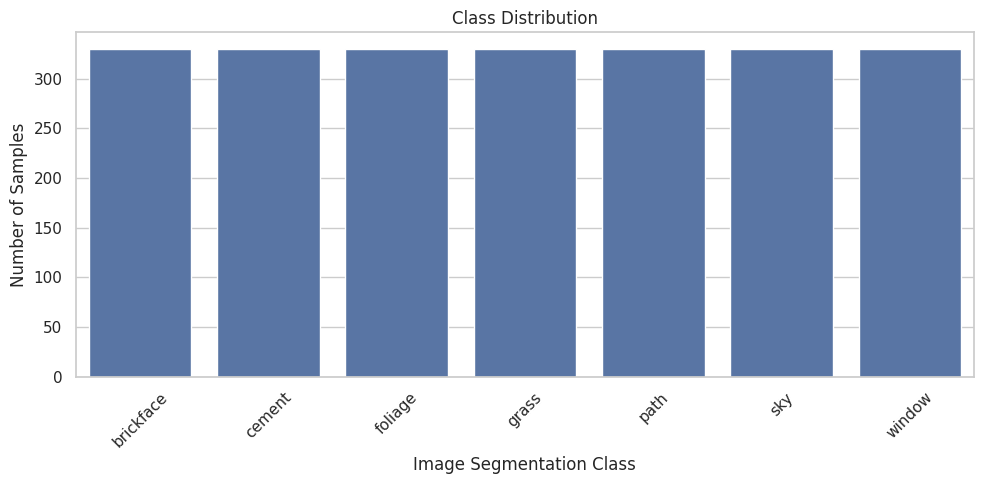

In [4]:

plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x="target",
    order=df["target"].value_counts().index
)

plt.title("Class Distribution")
plt.xlabel("Image Segmentation Class")
plt.ylabel("Number of Samples")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()



## 5. Statistical Analysis



In [5]:

display(X.describe().T)


,count,mean,std,min,25%,50%,75%,max
region-centroid-col,2310.0,124.913853,72.956532,1.000000e+00,62.000000,121.000000,189.000000,254.000000
region-centroid-row,2310.0,123.417316,57.483851,1.100000e+01,81.000000,122.000000,172.000000,251.000000
region-pixel-count,2310.0,9.000000,0.000000,9.000000e+00,9.000000,9.000000,9.000000,9.000000
short-line-density-5,2310.0,0.014334,0.040154,0.000000e+00,0.000000,0.000000,0.000000,0.333333
short-line-density-2,2310.0,0.004714,0.024234,0.000000e+00,0.000000,0.000000,0.000000,0.222222
vedge-mean,2310.0,1.893940,2.698909,0.000000e+00,0.722221,1.222220,2.166670,29.222200
vegde-sd,2310.0,5.709320,44.846453,0.000000e+00,0.355555,0.833333,1.806370,991.718000
hedge-mean,2310.0,2.424723,3.610083,0.000000e+00,0.777780,1.444440,2.555560,44.722200
hedge-sd,2310.0,8.243692,58.811528,-1.589460e-08,0.421637,0.962963,2.183272,1386.330000
intensity-mean,2310.0,37.051595,38.176410,0.000000e+00,7.296300,21.592600,53.213000,143.444000



## 6. Feature Distribution

 

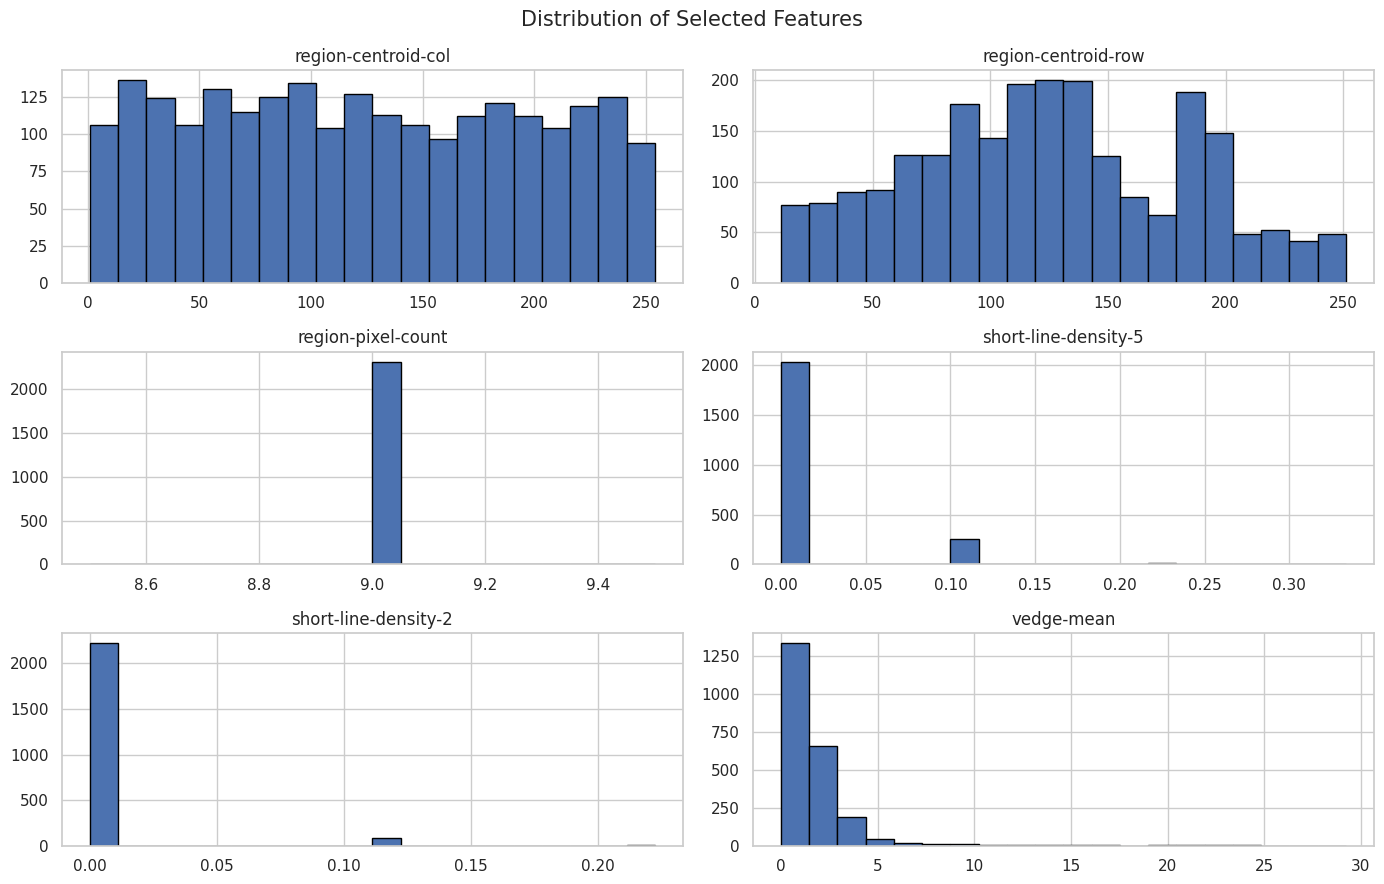

In [6]:

selected_features = X.columns[:6]

X[selected_features].hist(
    figsize=(14, 9),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Selected Features", fontsize=15)
plt.tight_layout()
plt.show()



## 7. Correlation Analysis



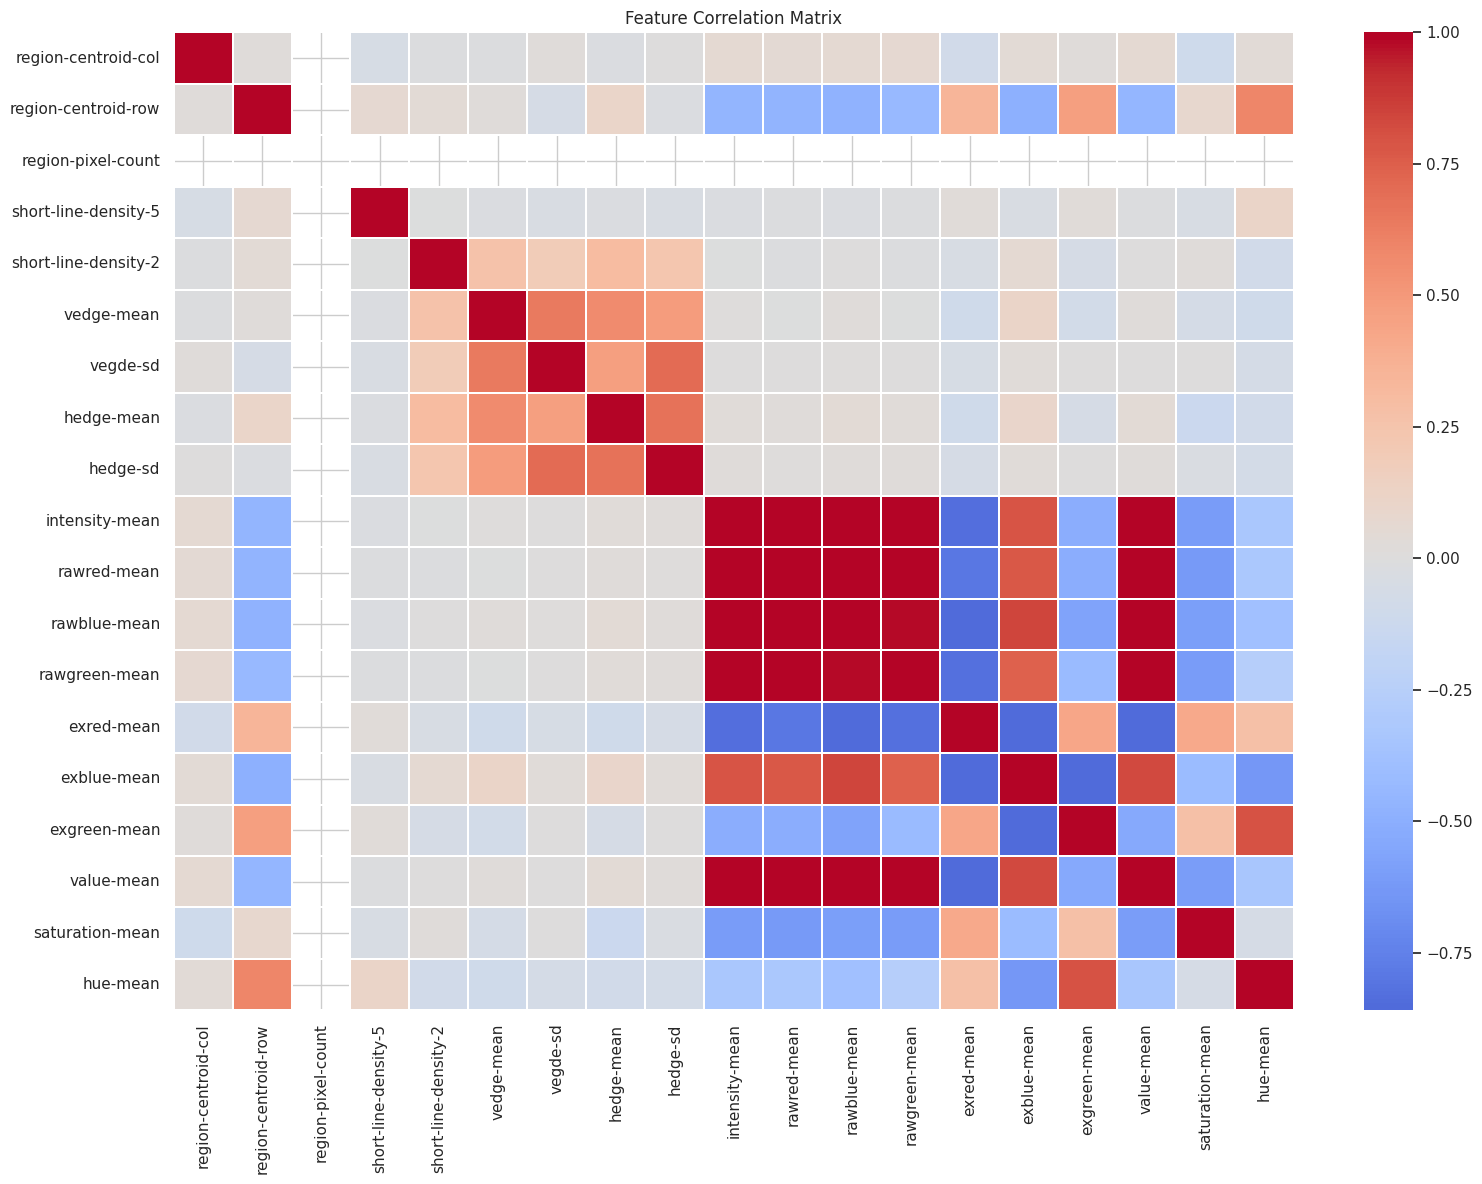

In [7]:

correlation_matrix = X.corr()

plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    linewidths=0.3
)

plt.title("Feature Correlation Matrix")
plt.tight_layout()
plt.show()



## 8. Data Preprocessing


In [8]:

label_encoder = LabelEncoder()

y_encoded = label_encoder.fit_transform(y)

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_encoded
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

print("\nTraining class distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTesting class distribution:")
print(pd.Series(y_test).value_counts().sort_index())

print("\nClass labels:")
print(label_encoder.classes_)


Training set shape: (1848, 19)
Testing set shape: (462, 19)

Training class distribution:
0    264
1    264
2    264
3    264
4    264
5    264
6    264
Name: count, dtype: int64

Testing class distribution:
0    66
1    66
2    66
3    66
4    66
5    66
6    66
Name: count, dtype: int64

Class labels:
['brickface' 'cement' 'foliage' 'grass' 'path' 'sky' 'window']



## 9. Feature Scaling




In [9]:

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Feature scaling completed successfully!")

print("Training data shape:", X_train_scaled.shape)
print("Testing data shape:", X_test_scaled.shape)

print("\nTraining data mean:", np.mean(X_train_scaled).round(4))
print("Training data standard deviation:", np.std(X_train_scaled).round(4))


Feature scaling completed successfully!
Training data shape: (1848, 19)
Testing data shape: (462, 19)

Training data mean: 0.0
Training data standard deviation: 0.9733



## 10. Kernel Functions


In [10]:

gamma_value = 1 / X_train_scaled.shape[1]

kernel_functions = {
    "Linear": linear_kernel,
    "Polynomial": polynomial_kernel,
    "RBF": rbf_kernel
}

K_train = {
    "Linear": linear_kernel(X_train_scaled, X_train_scaled),

    "Polynomial": polynomial_kernel(
        X_train_scaled,
        X_train_scaled,
        degree=3,
        gamma=gamma_value,
        coef0=1
    ),

    "RBF": rbf_kernel(
        X_train_scaled,
        X_train_scaled,
        gamma=gamma_value
    )
}

K_test = {
    "Linear": linear_kernel(X_test_scaled, X_train_scaled),

    "Polynomial": polynomial_kernel(
        X_test_scaled,
        X_train_scaled,
        degree=3,
        gamma=gamma_value,
        coef0=1
    ),

    "RBF": rbf_kernel(
        X_test_scaled,
        X_train_scaled,
        gamma=gamma_value
    )
}

for kernel_name in K_train:
    print(f"{kernel_name} Kernel:")
    print("Training matrix:", K_train[kernel_name].shape)
    print("Testing matrix:", K_test[kernel_name].shape)
    print("-" * 40)


Linear Kernel:
Training matrix: (1848, 1848)
Testing matrix: (462, 1848)
----------------------------------------
Polynomial Kernel:
Training matrix: (1848, 1848)
Testing matrix: (462, 1848)
----------------------------------------
RBF Kernel:
Training matrix: (1848, 1848)
Testing matrix: (462, 1848)
----------------------------------------



## 11. Kernel Feature Preparation


In [11]:

kernel_scalers = {}
K_train_scaled = {}
K_test_scaled = {}

for name in K_train:

    kernel_scalers[name] = StandardScaler()

    K_train_scaled[name] = kernel_scalers[name].fit_transform(
        K_train[name]
    )

    K_test_scaled[name] = kernel_scalers[name].transform(
        K_test[name]
    )

    print(f"{name} Kernel:")
    print("Training:", K_train_scaled[name].shape)
    print("Testing:", K_test_scaled[name].shape)
    print("-" * 40)


Linear Kernel:
Training: (1848, 1848)
Testing: (462, 1848)
----------------------------------------
Polynomial Kernel:
Training: (1848, 1848)
Testing: (462, 1848)
----------------------------------------
RBF Kernel:
Training: (1848, 1848)
Testing: (462, 1848)
----------------------------------------



## 12. Mini-batch Gradient Descent


In [12]:
def compute_loss(X, y, W, b, C):
    """Same objective used in training: 0.5*||W||^2 + (C/n) * sum(squared hinge)"""
    n_samples = X.shape[0]
    n_classes = W.shape[1]

    Y = -np.ones((n_samples, n_classes))
    Y[np.arange(n_samples), y] = 1

    margins = np.maximum(0, 1 - Y * (X @ W + b))

    return 0.5 * np.sum(W ** 2) + (C / n_samples) * np.sum(margins ** 2)


def train_minibatch_svm(X, y, learning_rate=0.0001, epochs=50, C=1,
                        batch_size=64, random_state=42):

    rng = np.random.default_rng(random_state)

    n_samples, n_features = X.shape
    n_classes = len(np.unique(y))

    Y = -np.ones((n_samples, n_classes))
    Y[np.arange(n_samples), y] = 1

    W = np.zeros((n_features, n_classes))
    b = np.zeros(n_classes)

    loss_history = []

    for epoch in range(epochs):

        # shuffle the samples at the start of every epoch
        indices = rng.permutation(n_samples)

        for start in range(0, n_samples, batch_size):

            batch_idx = indices[start:start + batch_size]

            X_batch = X[batch_idx]
            Y_batch = Y[batch_idx]

            scores = X_batch @ W + b
            margins = np.maximum(0, 1 - Y_batch * scores)
            error = Y_batch * margins

            # gradient computed on the mini-batch only (average over the batch)
            gradient_W = W - 2 * C * (X_batch.T @ error) / len(batch_idx)
            gradient_b = -2 * C * np.mean(error, axis=0)

            W = W - learning_rate * gradient_W
            b = b - learning_rate * gradient_b

        # loss on the whole training set after each epoch
        loss = compute_loss(X, y, W, b, C)
        loss_history.append(loss)

        if not np.isfinite(loss):
            break

    return W, b, loss_history

## 12.1 Hyperparameter Tuning (Validation Split)



In [13]:
fit_idx, val_idx = train_test_split(
    np.arange(len(y_train)),
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y_train
)

param_grid = {
    "C": [0.1, 1, 10, 100],
    "learning_rate": [0.00001, 0.0001, 0.001, 0.01]
}

TUNE_EPOCHS = 50

tuning_results = []

for kernel_name in K_train_scaled:

    K_all = K_train_scaled[kernel_name]

    for C in param_grid["C"]:
        for lr in param_grid["learning_rate"]:

            W, b, loss_history = train_minibatch_svm(
                K_all[fit_idx], y_train[fit_idx],
                learning_rate=lr, epochs=TUNE_EPOCHS, C=C
            )

            if np.isfinite(loss_history[-1]):
                val_pred = np.argmax(K_all[val_idx] @ W + b, axis=1)
                val_f1 = f1_score(y_train[val_idx], val_pred, average="macro", zero_division=0)
                val_acc = accuracy_score(y_train[val_idx], val_pred)
            else:
                val_f1, val_acc = np.nan, np.nan

            tuning_results.append({
                "Kernel": kernel_name,
                "C": C,
                "Learning Rate": lr,
                "Final Loss": loss_history[-1],
                "Val Accuracy": val_acc,
                "Val F1-Score": val_f1
            })

tuning_results = pd.DataFrame(tuning_results)

best_params = {}

for kernel_name in K_train_scaled:
    subset = tuning_results[tuning_results["Kernel"] == kernel_name]
    best_row = subset.loc[subset["Val F1-Score"].idxmax()]
    best_params[kernel_name] = {
        "C": best_row["C"],
        "learning_rate": best_row["Learning Rate"]
    }

print("Best hyperparameters (selected on validation set):")
print("=" * 50)
for kernel_name, params in best_params.items():
    print(f"{kernel_name}: C={params['C']}, learning_rate={params['learning_rate']}")

display(
    tuning_results.sort_values(
        by=["Kernel", "Val F1-Score"], ascending=[True, False]
    ).reset_index(drop=True)
)

Best hyperparameters (selected on validation set):
Linear: C=100.0, learning_rate=1e-05
Polynomial: C=100.0, learning_rate=1e-05
RBF: C=100.0, learning_rate=1e-05


,Kernel,C,Learning Rate,Final Loss,Val Accuracy,Val F1-Score
0,Linear,100.0,0.00001,170.018367,0.856757,0.845300
1,Linear,10.0,0.00010,17.090706,0.854054,0.842403
2,Linear,1.0,0.00100,1.766107,0.848649,0.835704
3,Linear,1.0,0.00010,3.499484,0.827027,0.801717
4,Linear,10.0,0.00001,34.504016,0.827027,0.801717
5,Linear,0.1,0.00100,0.379746,0.827027,0.800641
6,Linear,0.1,0.01000,0.207923,0.802703,0.783233
7,Linear,1.0,0.00001,4.952178,0.781081,0.754239
8,Linear,0.1,0.00010,0.503936,0.778378,0.751848
9,Linear,0.1,0.00001,0.602930,0.651351,0.620448



## 13. Model Training



In [14]:
FINAL_EPOCHS = 200

mb_models = {}
mb_training_results = []

for kernel_name in K_train_scaled:

    params = best_params[kernel_name]

    print(f"Training Mini-batch with {kernel_name} Kernel "
          f"(C={params['C']}, lr={params['learning_rate']})...")

    start_time = time.time()

    W, b, loss_history = train_minibatch_svm(
        K_train_scaled[kernel_name], y_train,
        learning_rate=params["learning_rate"],
        epochs=FINAL_EPOCHS,
        C=params["C"]
    )

    training_time = time.time() - start_time

    mb_models[kernel_name] = {"W": W, "b": b, "loss_history": loss_history, "C": params["C"]}

    mb_training_results.append({
        "Kernel": kernel_name,
        "C": params["C"],
        "Learning Rate": params["learning_rate"],
        "Training Time (s)": round(training_time, 2),
        "Initial Loss": loss_history[0],
        "Final Loss": loss_history[-1],
        "Epochs": len(loss_history)
    })

    print("Done in", round(training_time, 2), "seconds | Final loss:", round(loss_history[-1], 4))
    print("-" * 40)

mb_training_results = pd.DataFrame(mb_training_results)
display(mb_training_results)

Training Mini-batch with Linear Kernel (C=100.0, lr=1e-05)...
Done in 4.44 seconds | Final loss: 90.0854
----------------------------------------
Training Mini-batch with Polynomial Kernel (C=100.0, lr=1e-05)...
Done in 4.33 seconds | Final loss: 56.483
----------------------------------------
Training Mini-batch with RBF Kernel (C=100.0, lr=1e-05)...
Done in 4.49 seconds | Final loss: 47.6569
----------------------------------------


,Kernel,C,Learning Rate,Training Time (s),Initial Loss,Final Loss,Epochs
0,Linear,100.0,0.00001,4.44,618.186616,90.085384,200
1,Polynomial,100.0,0.00001,4.33,392.104843,56.482996,200
2,RBF,100.0,0.00001,4.49,415.009911,47.656878,200



## 14. Loss Visualization



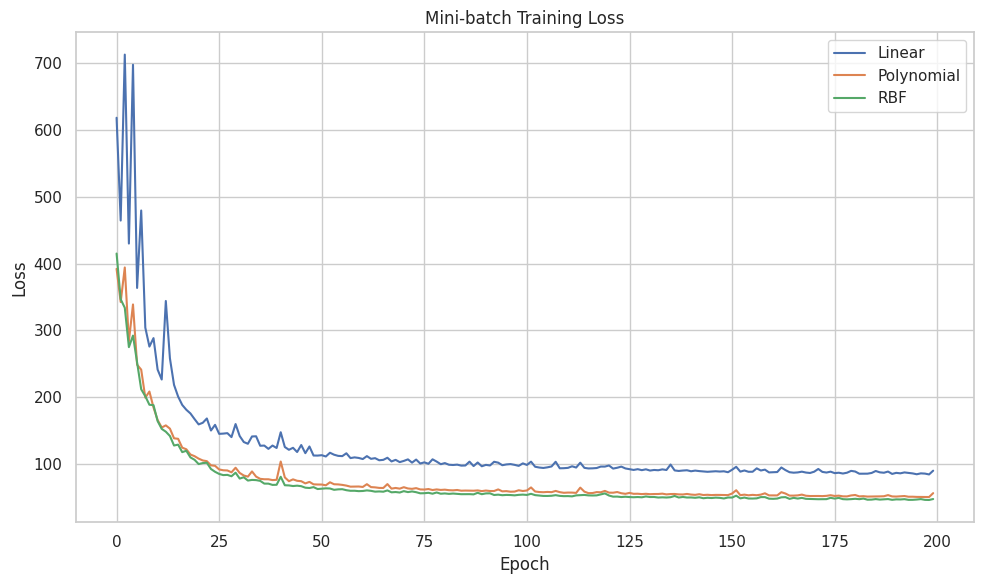

In [15]:
plt.figure(figsize=(10, 6))

for kernel_name, model in mb_models.items():
    plt.plot(model["loss_history"], label=kernel_name)

plt.title("Mini-batch Training Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.show()


## 15. Model Evaluation


In [16]:
mb_predictions = {}
mb_evaluation_results = []

for kernel_name in K_test_scaled:

    model = mb_models[kernel_name]

    scores = K_test_scaled[kernel_name] @ model["W"] + model["b"]
    predictions = np.argmax(scores, axis=1)

    mb_predictions[kernel_name] = predictions

    mb_evaluation_results.append({
        "Kernel": kernel_name,
        "Accuracy": accuracy_score(y_test, predictions),
        "Precision": precision_score(y_test, predictions, average="macro", zero_division=0),
        "Recall": recall_score(y_test, predictions, average="macro", zero_division=0),
        "F1-Score": f1_score(y_test, predictions, average="macro", zero_division=0),
        "Train Loss": model["loss_history"][-1],
        "Test Loss": compute_loss(K_test_scaled[kernel_name], y_test,
                                  model["W"], model["b"], model["C"])
    })

mb_evaluation = pd.DataFrame(mb_evaluation_results)

display(mb_evaluation.sort_values(by="Accuracy", ascending=False).reset_index(drop=True))

,Kernel,Accuracy,Precision,Recall,F1-Score,Train Loss,Test Loss
0,RBF,0.928571,0.931356,0.928571,0.928835,47.656878,57.884936
1,Polynomial,0.911255,0.919493,0.911255,0.911513,56.482996,65.174785
2,Linear,0.880952,0.893829,0.880952,0.878353,90.085384,103.087137



## 16. Classification Reports


In [17]:
for kernel_name, predictions in mb_predictions.items():

    print(f"\n{kernel_name} Kernel Classification Report")
    print("=" * 60)

    print(classification_report(
        y_test,
        predictions,
        labels=np.arange(len(label_encoder.classes_)),
        target_names=label_encoder.classes_,
        zero_division=0
    ))


Linear Kernel Classification Report
              precision    recall  f1-score   support

   brickface       0.93      0.98      0.96        66
      cement       0.98      0.62      0.76        66
     foliage       0.84      0.73      0.78        66
       grass       1.00      0.97      0.98        66
        path       0.81      1.00      0.90        66
         sky       1.00      1.00      1.00        66
      window       0.70      0.86      0.77        66

    accuracy                           0.88       462
   macro avg       0.89      0.88      0.88       462
weighted avg       0.89      0.88      0.88       462


Polynomial Kernel Classification Report
              precision    recall  f1-score   support

   brickface       0.98      0.98      0.98        66
      cement       0.94      0.89      0.91        66
     foliage       0.88      0.67      0.76        66
       grass       1.00      0.97      0.98        66
        path       0.96      1.00      0.98        66



## 17. Confusion Matrices


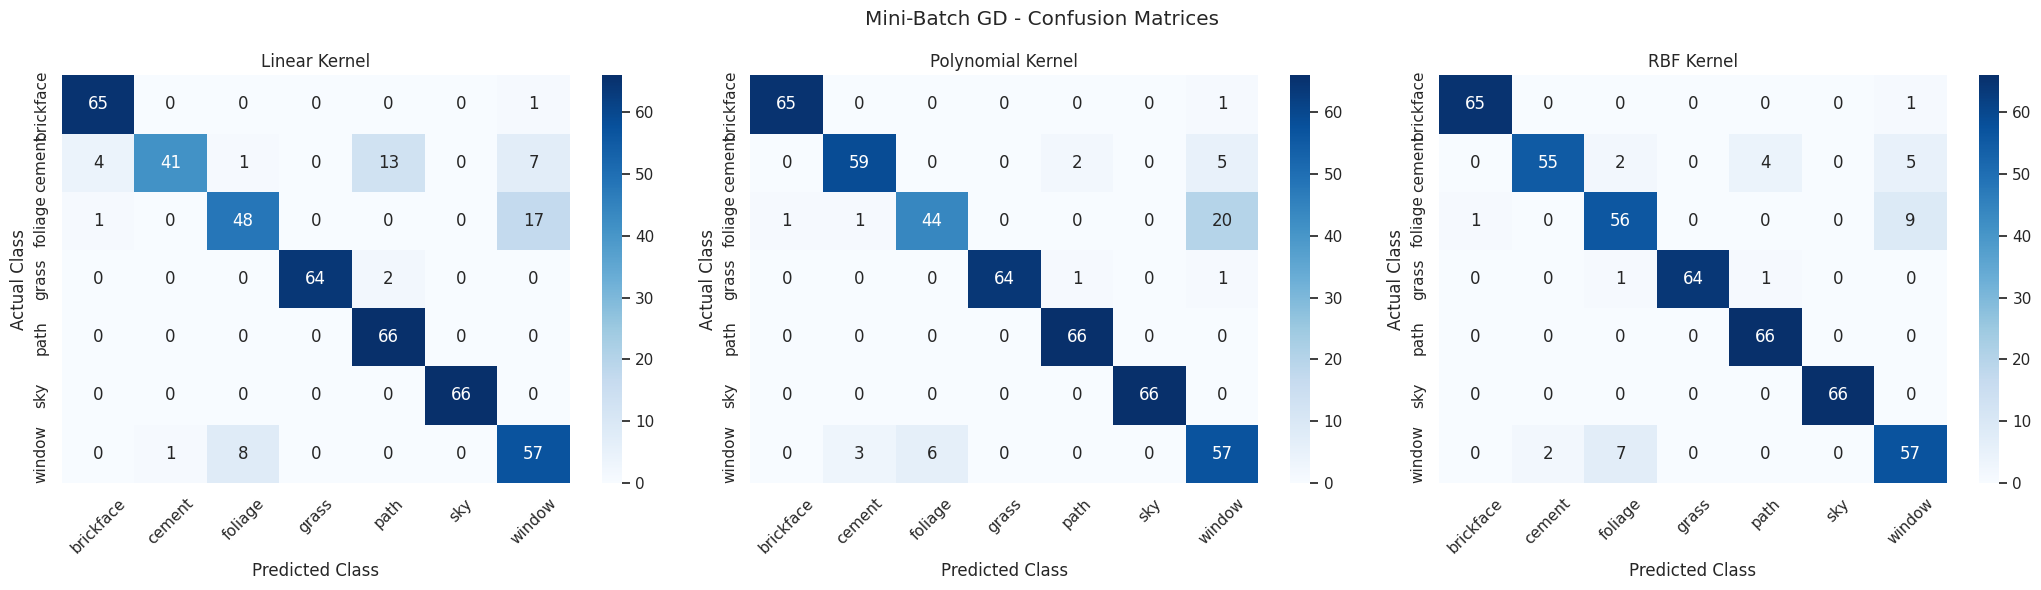

In [18]:
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

for ax, (kernel_name, predictions) in zip(
    axes,
    mb_predictions.items()
):

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=np.arange(len(label_encoder.classes_))
    )

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues",
        xticklabels=label_encoder.classes_,
        yticklabels=label_encoder.classes_,
        ax=ax
    )

    ax.set_title(f"{kernel_name} Kernel")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")
    ax.tick_params(axis="x", rotation=45)

plt.suptitle("Mini-Batch GD - Confusion Matrices")
plt.tight_layout()
plt.show()


## 18. Kernel Performance Comparison



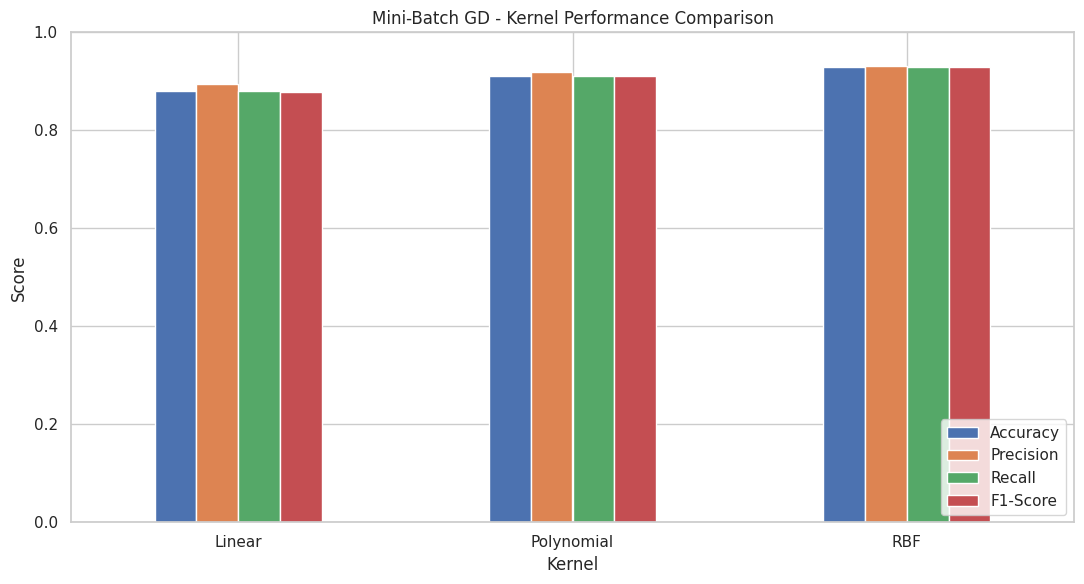

In [19]:
metrics = [
    "Accuracy",
    "Precision",
    "Recall",
    "F1-Score"
]

mb_evaluation.set_index("Kernel")[metrics].plot(
    kind="bar",
    figsize=(11, 6),
    ylim=(0, 1)
)

plt.title("Mini-Batch GD - Kernel Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Kernel")
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


## 19. Best Mini Batch Model



In [20]:
best_mb_model = mb_evaluation.loc[
    mb_evaluation["F1-Score"].idxmax()
]

print("Best Mini-Batch GD Model")
print("=" * 40)

print("Kernel:", best_mb_model["Kernel"])
print("Accuracy:", round(best_mb_model["Accuracy"], 4))
print("Precision:", round(best_mb_model["Precision"], 4))
print("Recall:", round(best_mb_model["Recall"], 4))
print("F1-Score:", round(best_mb_model["F1-Score"], 4))
print("Train Loss:", round(best_mb_model["Train Loss"], 4))
print("Test Loss:", round(best_mb_model["Test Loss"], 4))

Best Mini-Batch GD Model
Kernel: RBF
Accuracy: 0.9286
Precision: 0.9314
Recall: 0.9286
F1-Score: 0.9288
Train Loss: 47.6569
Test Loss: 57.8849
